Author:  
Manuel Eugenio Morocho Cayamcela, PhD

Estudiante: María Brigith Suárez Rodríguez 

# **Unsupervised Learning**
## Mall Customer Clustering with KMeans

### **Introduction**

This activity introduces clustering using the `mall_customers.csv` dataset, which contains information about shopping mall customers, including a variable that represents their spending behavior.

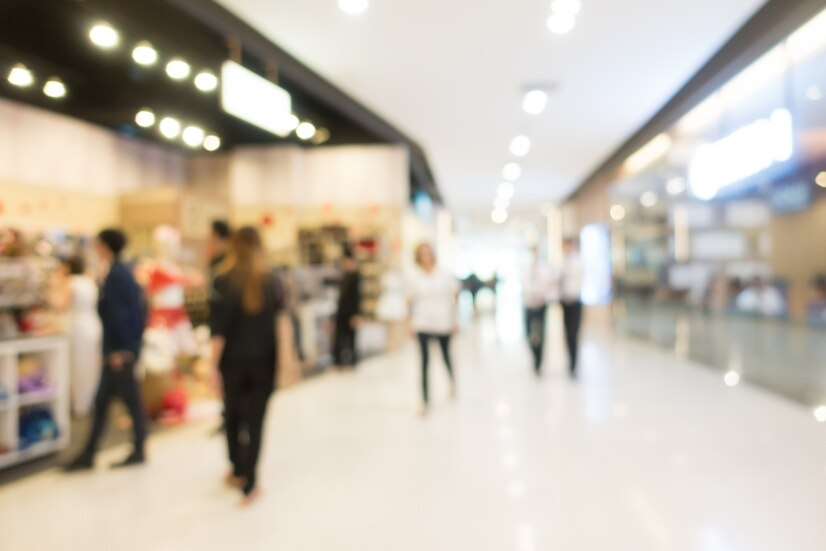

The `mall_customers.csv` dataset contains the following variables:

1. `CustomerID`: A unique identifier for each customer. It is an integer that increases by 1 for each customer.

2. `Gender`: The customer's gender. This is a categorical variable with two possible values: 'Male' and 'Female'.

3. `Age`: The customer's age. This is a numerical variable.

4. `Annual Income (k$)`: The customer's annual income in thousands of dollars. This is a numerical variable.

5. `Spending Score (1-100)`: The customer's spending score on a scale from 1 to 100. This is a numerical variable that indicates how much the customer spends or reflects their purchasing behavior.

The spending score measures how much a customer spends at a particular business over a given period. This metric is essential for understanding customer purchasing behavior and segmenting customers into groups with similar characteristics. But how is this score calculated, and where does it come from in a real company?

The spending score is derived from a combination of factors, such as visit frequency, average purchase value, and total spending over a specific period. Businesses often use customer tracking systems, such as loyalty programs, loyalty cards, or point-of-sale (POS) systems, to collect purchase data. These systems record each customer transaction, including the amount spent, items purchased, and visit frequency.

Using this information, businesses can calculate the spending score in various ways, such as assigning points to each purchase based on its value or frequency, or using more complex algorithms that consider multiple variables. The goal is to create a metric that accurately and meaningfully reflects each customer's purchasing behavior.

In the real world, spending scores are used across many industries, including retail, restaurants, hotels, and financial services. Businesses use them to better understand customers, identify purchasing patterns, design targeted marketing strategies, and improve the customer experience.

### **Content**

#### Import the required packages

In [12]:
# Install the required packages
%pip install scikit-learn
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install ipywidgets
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
# Import the required packages
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#### Load the dataset

In [14]:
# Load the 'mall_customers.csv' dataset
customers = pd.read_csv(r"C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 2\mall_customers(in).csv")

#### Display the first 10 rows of the loaded dataset

In [15]:
# Display the first rows
customers.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [16]:
# Display information about the dataset
customers.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


array([[<Axes: title={'center': 'CustomerID'}>,
        <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Annual Income (k$)'}>,
        <Axes: title={'center': 'Spending Score (1-100)'}>]], dtype=object)

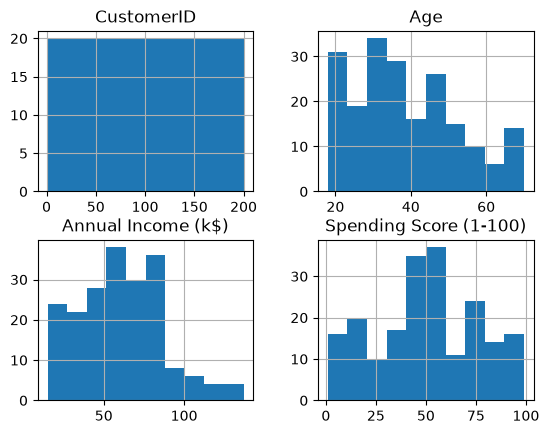

In [17]:
# Display histograms of the variables
customers.hist()

#### Remove columns that do not provide useful information for the analysis

The `CustomerID` column is a unique identifier for each customer. In most cases, identifiers like this do not provide useful information for data analysis or data mining models because they are not related to the other variables. Therefore, this column is commonly removed before analysis.

The pandas `drop` method removes the specified column (`'CustomerID'`) from the DataFrame. The `axis=1` argument indicates that we want to remove a column rather than a row. The resulting DataFrame is assigned back to the `customers` variable.

In [18]:
# Remove the 'CustomerID' column
customers = customers.drop('CustomerID', axis=1)
customers.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
5,Female,22,17,76
6,Female,35,18,6
7,Female,23,18,94
8,Male,64,19,3
9,Female,30,19,72


#### Encode the categorical 'Gender' column

We use the pandas `replace` method to replace values in the `Gender` column of the `customers` DataFrame.

- `customers['Gender']`: Selects the `Gender` column from the `customers` DataFrame.

- `replace({'Female': 0, 'Male': 1})`: Replaces values in the column according to the provided mapping. In this case, it replaces 'Female' with 0 and 'Male' with 1. This is called label encoding.

The purpose of this code is to convert the categorical `Gender` variable into a numerical variable, which is useful for calculating correlations between variables.

In [19]:
# Encode the 'Gender' variable
customers['Gender'] = customers['Gender'].replace({'Female': 0, 'Male': 1})
customers.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40
5,0,22,17,76
6,0,35,18,6
7,0,23,18,94
8,1,64,19,3
9,0,30,19,72


#### Use `ydata_profiling` to profile the data

The `ydata_profiling` tool is very useful for exploratory data analysis. This Python library generates detailed data profiles from a pandas DataFrame, providing a quick, comprehensive overview of the data structure, relationships, and distributions.

With `ydata_profiling`, you can generate a comprehensive report from your dataset with just a few lines of code. The report includes descriptive statistics, variable distributions, correlations, missing values, and more. This can be extremely useful at the start of any data analysis or data mining project because it helps you understand your data before preprocessing or modeling.

Keep in mind that `ydata_profiling` is a data analysis tool and does not replace careful analysis or a thorough understanding of your data. Always verify and understand the results it provides.

In [20]:
# Install the ydata-profiling library
%pip install ydata-profiling
%pip install setuptools 

# Import ProfileReport from ydata_profiling
from ydata_profiling import ProfileReport

Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following versions that require a different python version: 4.0.0 Requires-Python >=3.7,<3.11; 4.1.0 Requires-Python >=3.7,<3.12; 4.1.1 Requires-Python >=3.7,<3.12; 4.1.2 Requires-Python >=3.7,<3.12; 4.10.0 Requires-Python >=3.7,<3.13; 4.11.0 Requires-Python >=3.7,<3.13; 4.12.0 Requires-Python >=3.7,<3.13; 4.12.1 Requires-Python >=3.7,<3.13; 4.12.2 Requires-Python >=3.7,<3.13; 4.13.0 Requires-Python >=3.7,<3.13; 4.14.0 Requires-Python >=3.7,<3.13; 4.15.0 Requires-Python >=3.7,<3.13; 4.15.1 Requires-Python >=3.7,<3.13; 4.16.0 Requires-Python >=3.7,<3.13; 4.16.1 Requires-Python >=3.7,<3.13; 4.17.0 Requires-Python >=3.7,<3.14; 4.18.0 Requires-Python >=3.10,<3.14; 4.18.1 Requires-Python >=3.10,<3.14; 4.18.4 Requires-Python >=3.10,<3.14; 4.2.0 Requires-Python >=3.7,<3.12; 4.3.0 Requires-Python >=3.7,<3.12; 4.3.1 Requires-Python >=3.7,<3.12; 4.3.2 Requires-Python >=3.7,<3.12; 4.4.0 Requires-Python >=3.7,<3.12; 4.5.0 Requires-Python >=3.7,<3.12; 4.5.1 Requires-Python >=3.7,

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


ModuleNotFoundError: No module named 'ydata_profiling'

- `customers`: The pandas DataFrame to profile.

- `title='Customer Data Profile Report'`: Sets the report title.

- `explorative=True`: Indicates that the report should be exploratory, including more information and analysis than a standard profiling report.

The data profiling report provides a quick overview of your dataset, including data types, unique values, missing values, descriptive statistics, correlations, and variable distributions.

To display the report, call the `customer_profile` object in a Jupyter Notebook cell.

In [21]:
# Generate the data profiling report
customer_profile = ProfileReport(customers, title='Customer Data Profile Report', explorative=True)

NameError: name 'ProfileReport' is not defined

In [10]:
# Display the data profiling report
customer_profile.to_notebook_iframe()

NameError: name 'customer_profile' is not defined

In [11]:
customer_profile.to_file('customer_profile_report.html')

NameError: name 'customer_profile' is not defined

#### Plot the distributions of the variables

The distribution of variables in a dataset can provide valuable information about its characteristics. Here are some things to examine:

**Central tendency**: The mean and median indicate where the data are centered.

**Dispersion**: The standard deviation and interquartile range indicate how spread out the data are around the mean.

**Skewness**: A left or right skew may indicate outliers or a non-uniform distribution.

**Outliers**: Values significantly distant from the rest of the data may indicate measurement errors or natural variation.

**Multimodal distribution**: More than one peak may indicate subgroups within the data.

The scatter plot of `Annual Income (k$)` and `Spending Score (1-100)` reveals visible data groupings, suggesting that there are groups of customers with similar spending behavior relative to their annual income.

We create a new DataFrame containing only these two variables to examine these groupings more closely and apply clustering techniques to identify and define the groups more formally.

This can provide valuable information for marketing strategy by allowing customers to be segmented according to their spending behavior and income. This, in turn, can inform decisions about targeted offers and promotions, personalized customer communications, and more.

In [22]:
# Create a DataFrame containing only the 'Annual Income (k$)' and 'Spending Score (1-100)' columns
income_spending = customers[['Annual Income (k$)', 'Spending Score (1-100)']]
income_spending.head(10)

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
5,17,76
6,18,6
7,18,94
8,19,3
9,19,72


#### Plot the distributions of 'Annual Income (k$)' and 'Spending Score (1-100)'

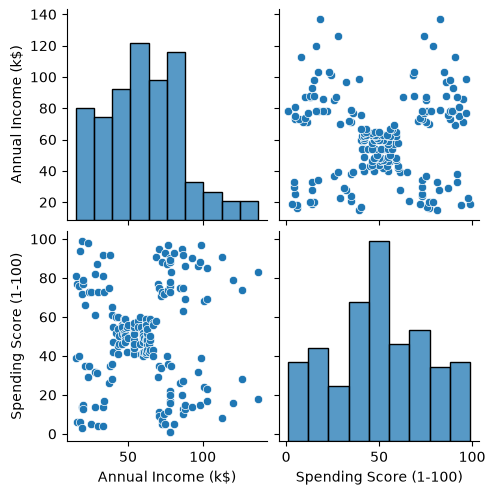

In [23]:
# Plot the distributions in income_spending
sns.pairplot(income_spending)

#### Cluster the 'income_spending' DataFrame using the KMeans algorithm

We use KMeans clustering on the `income_spending` DataFrame to find 2 clusters, then add the cluster labels to the data.

- `kmeans_model = KMeans(n_clusters=2)`: Creates a KMeans model with 2 clusters. The number of clusters is a parameter that must be specified.

- `kmeans_model.fit(income_spending)`: Fits the model to the `income_spending` data. KMeans attempts to find cluster centers that minimize the variance within each cluster.

- `income_spending['Cluster'] = kmeans_model.labels_`: After fitting the model, the `labels_` attribute provides the cluster label for each data point. This line adds the labels as a new column in the `income_spending` DataFrame.

- `income_spending.head(10)`: Displays the first 10 rows of the `income_spending` DataFrame, now including the `Cluster` column.

In [24]:
# Instantiate the KMeans model
kmeans_model = KMeans(n_clusters=2, random_state=75)

# Fit the model to the data
kmeans_model.fit(income_spending)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",75
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)","[

In [25]:
# Copy the 'income_spending' DataFrame to preserve the original and add the clusters
income_spending_cluster = income_spending.copy()

# Get the cluster labels assigned to each customer
income_spending_cluster['Cluster'] = kmeans_model.labels_

# Display the first rows of 'income_spending_cluster'
income_spending_cluster.head(10)

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,1
1,15,81,1
2,16,6,1
3,16,77,1
4,17,40,1
5,17,76,1
6,18,6,1
7,18,94,1
8,19,3,1
9,19,72,1


In [26]:
income_spending_cluster.tail(10)

,Annual Income (k$),Spending Score (1-100),Cluster
190,103,23,0
191,103,69,0
192,113,8,0
193,113,91,0
194,120,16,0
195,120,79,0
196,126,28,0
197,126,74,0
198,137,18,0
199,137,83,0


We create a pair plot of the `income_spending` variables and color the points according to the clusters identified by KMeans. This helps us visualize how the clusters are distributed in the variable space.

- `sns.pairplot(income_spending)`: Creates a pair plot of all variables in the DataFrame. A pair plot shows the relationship between each pair of variables in a dataset.

- `hue='Cluster'`: Specifies that points in the plot should be colored according to the `Cluster` column. This makes it possible to visualize the distribution of clusters for each pair of variables.

- `palette='viridis'`: Sets the color palette for the clusters. 'viridis' is a perceptually uniform palette that is easy to interpret.

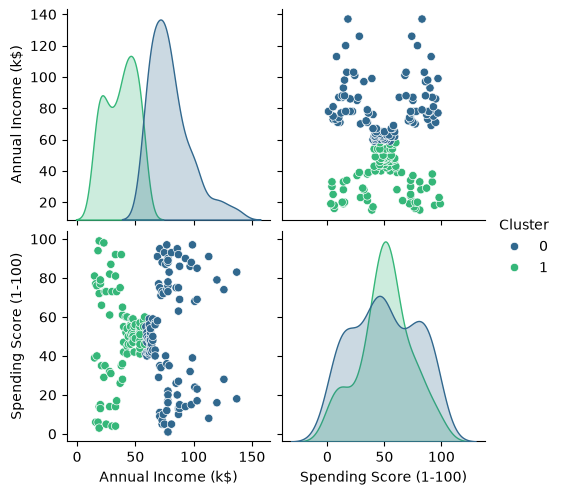

In [27]:
# Display the clusters generated by the KMeans model
sns.pairplot(income_spending_cluster, hue='Cluster', palette='viridis')

In [28]:
# Get the inertia of the KMeans model
inertia = kmeans_model.inertia_
inertia

181363.59595959596

Finally, we can use the previously fitted KMeans model to predict the cluster of a new customer based on their features.

- `new_customer = [ , ]`: Creates a list representing a new customer's data. The values correspond to the customer's annual income and spending score.

- `new_customer_cluster = kmeans_model.predict([new_customer])`: Uses the KMeans model's `predict` method to predict which cluster the new customer belongs to. The method takes a list of lists as input, where each inner list represents one customer's data. Here, the input contains only one customer: `[new_customer]`.

- `print('The new customer belongs to cluster:', new_customer_cluster)`: Prints the cluster assigned to the new customer. The `predict` method returns a list of cluster labels, one for each customer in the input. Here, the list contains a single label.

In [29]:
# New customer with Annual Income (k$) = 50 and Spending Score (1-100) = 50
new_customer_cluster = kmeans_model.predict([[50, 50]])
new_customer_cluster

c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1], dtype=int32)

### **Group Assignment**

We can see that 2 may not be the optimal value of $k$. Let's try to find the best value of $k$ using the elbow method. This method involves running the KMeans clustering algorithm for a range of $k$ values and then plotting the number of clusters against the sum of squared distances within each cluster (inertia).

> Inertia is calculated by measuring the distance between a data point and its centroid, squaring the distance, and summing those squared distances for all data points in the cluster.

The 'elbow' in this plot—the inflection point where the rate of decrease becomes significantly smaller—may indicate a good value for $k$.

### **Code (4 points)**

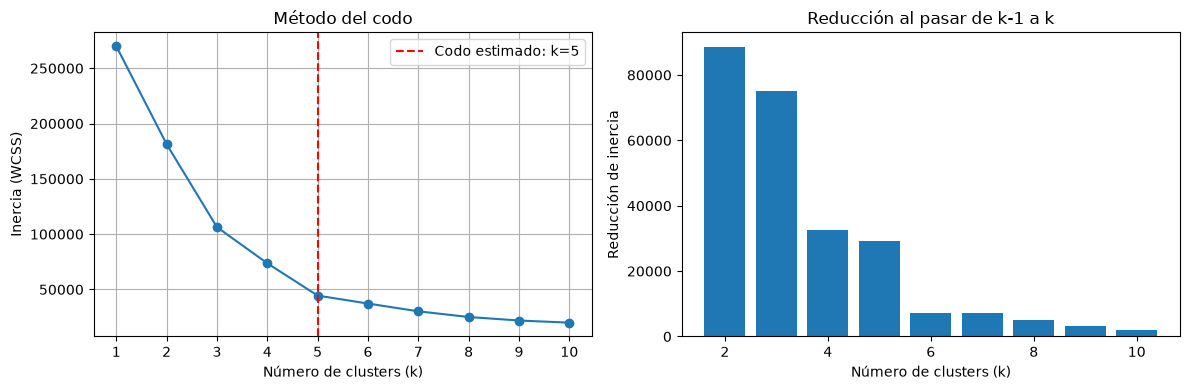

 k  inercia  reducción vs. k anterior  % reducción
 1 269981.0                       NaN          NaN
 2 181364.0                   88618.0         32.8
 3 106348.0                   75015.0         41.4
 4  73680.0                   32669.0         30.7
 5  44448.0                   29231.0         39.7
 6  37266.0                    7183.0         16.2
 7  30228.0                    7038.0         18.9
 8  25096.0                    5132.0         17.0
 9  21914.0                    3182.0         12.7
10  19968.0                    1946.0          8.9

Número de clusters estimado por el método del codo: 5


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# El archivo CSV debe estar en la misma carpeta que el notebook
customers = pd.read_csv("mall_customers(in).csv")

# Seleccionar las columnas para el agrupamiento
income_spending = customers[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].dropna()

# Calcular una inercia para cada valor de k
K_RANGE = range(1, 11)
inertias = []

for k in K_RANGE:
    model = KMeans(n_clusters=k, random_state=75, n_init=10)
    model.fit(income_spending)
    inertias.append(model.inertia_)

ks = np.array(list(K_RANGE))
inr = np.array(inertias)

# Estimar el codo automáticamente
x_norm = (ks - ks.min()) / (ks.max() - ks.min())
y_norm = (inr - inr.min()) / (inr.max() - inr.min())
distances = np.abs(x_norm + y_norm - 1) / np.sqrt(2)
k_elbow = int(ks[distances.argmax()])

# Graficar
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ks, inr, marker="o")
axes[0].axvline(
    k_elbow,
    linestyle="--",
    color="red",
    label=f"Codo estimado: k={k_elbow}"
)
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_title("Método del codo")
axes[0].set_xticks(ks)
axes[0].grid(True)
axes[0].legend()

axes[1].bar(ks[1:], -np.diff(inr), color="tab:blue")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Reducción de inercia")
axes[1].set_title("Reducción al pasar de k-1 a k")

plt.tight_layout()
plt.show()

resultados = pd.DataFrame({
    "k": ks,
    "inercia": inr.round(0),
    "reducción vs. k anterior": [np.nan] + list((-np.diff(inr)).round(0)),
    "% reducción": [np.nan] + list((-np.diff(inr) / inr[:-1] * 100).round(1))
})

print(resultados.to_string(index=False))
print(f"\nNúmero de clusters estimado por el método del codo: {k_elbow}")

Analysis Questions - New Dataset

Assessment Rubric (10 points)

Phase 1 - Dataset and Features (3 points)
1 point: The dataset is locally sourced, and its source is identified.
1 point: Every dataset variable is described.
1 point: The features selected for the model are justified.

Phase 2 - KMeans Modeling (4 points)
2 points: The elbow method is applied to a range of k values, and the plot and selected k are provided.
2 points: KMeans is fitted using the selected k, and the resulting clusters are visualized.

Phase 3 - Findings (3 points)
1 point each: Three findings are stated, and each is supported by the clustering results.

***1. Which customer group would you focus on? (2 points)***

Identify the cluster and describe its profile using the clustering results to support your choice.

Con el método del codo se estimaron 5 clusters, sin embargo, de estos cluster hay 3 que contienen 39 clientes que representan un ingreso anual promedio de 86,500.00 y un puntaje promedio del 82%. Ese es el grupo con el mayor poder adquisitivo y tambien con un alto gasto, siendo los principales tipod de personas que podrian responder a ofertas premium, programas de fidelización y beneficios exclusivos. 

***2. What actionable strategies could we recommend to increase spending at the shopping mall?***

Dirigir una campaña al cluster 2 ya que tienen un ingreso anual promedio de 88.200,00 pero un gasto promedio bajo de 17,1%, por lo que, se demuestra la necesidad de implementar campañas que incentiven su consumo. 

Se podrían ofrecer beneficios personalizados por compras en varias tiendas —por ejemplo, puntos extra o un cupón para una próxima visita al alcanzar un monto mínimo— y medir si aumenta su gasto. Así se incentiva una mayor compra sin aplicar descuentos generales a todos los clientes.

***3. Which group would a new customer with an annual income (k$) of 110 and a spending score of 21 belong to?***

In [31]:
# Create a record with the new customer's values and assign it to a cluster using the trained KMeans model.
new_customer = [50, 50]
# Use the KMeans model's predict method to predict the cluster of the new customer.
new_customer_cluster = kmeans_model.predict([new_customer])

print("Cluster asignado:", new_customer_cluster[0])

Cluster asignado: 1


c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


Con el modelo de 2 clusters el nuevo cliente pertenecería al cluster 0. El modelo agrupa ahí a los clientes con ingresos relativamente altos; el centro de ese cluster está aproximadamente en 79,600.00 de ingreso y 50,1 puntos de gasto.